<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/Marketing_Campaign_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1000 non-null   int64  
 1   Age               1000 non-null   int64  
 2   Gender            1000 non-null   object 
 3   Annual_Income_k   1000 non-null   int64  
 4   Campaign_Channel  1000 non-null   object 
 5   Ad_Spend          1000 non-null   float64
 6   Clicks            1000 non-null   int64  
 7   Conversion        1000 non-null   int64  
 8   Revenue           1000 non-null   float64
 9   CTR_pct           1000 non-null   float64
dtypes: float64(3), int64(5), object(2)
memory usage: 78.3+ KB
None

--- First 5 Rows ---


,Customer_ID,Age,Gender,Annual_Income_k,Campaign_Channel,Ad_Spend,Clicks,Conversion,Revenue,CTR_pct
0,1,56,Female,48,Social Media,461.78,146,0,0.0,31.62
1,2,69,Male,60,Email,163.03,282,0,0.0,172.97
2,3,46,Male,83,Email,429.90,126,0,0.0,29.31
3,4,32,Male,67,Social Media,267.81,103,0,0.0,38.46
4,5,60,Male,99,Referral,281.34,177,0,0.0,62.91



--- Missing Values ---
Customer_ID         0
Age                 0
Gender              0
Annual_Income_k     0
Campaign_Channel    0
Ad_Spend            0
Clicks              0
Conversion          0
Revenue             0
CTR_pct             0
dtype: int64

--- Statistical Summary ---


,Customer_ID,Age,Annual_Income_k,Ad_Spend,Clicks,Conversion,Revenue,CTR_pct
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,43.81900,64.926000,268.738530,149.640000,0.148000,79.797550,79.649740
std,288.819436,14.99103,14.838285,129.984646,83.346392,0.355278,217.909897,81.506807
min,1.000000,18.00000,19.000000,50.010000,10.000000,0.000000,0.000000,2.510000
25%,250.750000,31.00000,55.000000,155.210000,78.000000,0.000000,0.000000,29.517500
50%,500.500000,44.00000,65.000000,265.960000,150.000000,0.000000,0.000000,54.215000
75%,750.250000,56.00000,75.000000,378.602500,222.250000,0.000000,0.000000,93.360000
max,1000.000000,69.00000,112.000000,498.990000,298.000000,1.000000,990.350000,544.910000


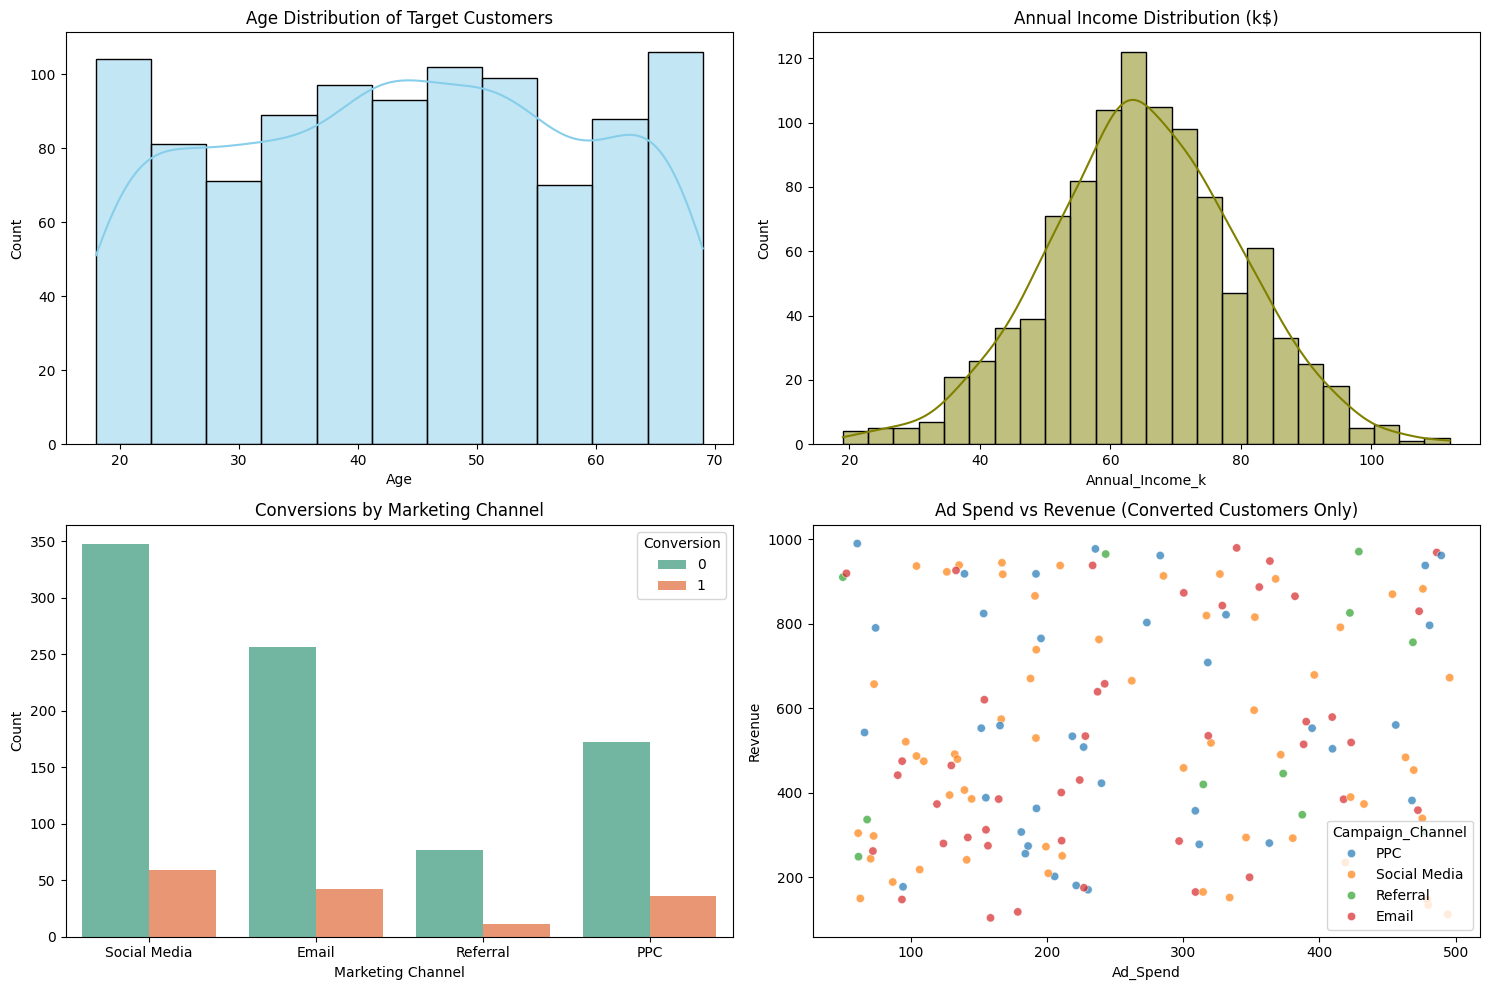


--- Channel Performance Summary ---


,Campaign_Channel,Total_Spend,Total_Revenue,Total_Conversions,Total_Customers,Conversion_Rate_pct,ROI_pct
0,Email,80047.85,21760.52,42,298,14.09,-72.82
1,PPC,55230.88,20525.60,36,208,17.31,-62.84
2,Referral,22960.98,6534.50,11,88,12.50,-71.54
3,Social Media,110498.82,30976.93,59,406,14.53,-71.97


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate Synthetic Marketing Campaign Data for EDA
np.random.seed(42)
n_samples = 1000

data = {
    'Customer_ID': range(1, n_samples + 1),
    'Age': np.random.randint(18, 70, size=n_samples),
    'Gender': np.random.choice(['Male', 'Female', 'Other'], size=n_samples, p=[0.48, 0.48, 0.04]),
    'Annual_Income_k': np.random.normal(65, 15, size=n_samples).astype(int),
    'Campaign_Channel': np.random.choice(['Social Media', 'Email', 'PPC', 'Referral'], size=n_samples, p=[0.4, 0.3, 0.2, 0.1]),
    'Ad_Spend': np.random.uniform(50, 500, size=n_samples).round(2),
    'Clicks': np.random.randint(10, 300, size=n_samples),
    'Conversion': np.random.choice([0, 1], size=n_samples, p=[0.85, 0.15]),
    'Revenue': np.zeros(n_samples)
}

df = pd.DataFrame(data)
# Revenue is generated only if a conversion occurred
df.loc[df['Conversion'] == 1, 'Revenue'] = np.random.uniform(100, 1000, size=df['Conversion'].sum()).round(2)

# Calculate basic performance metrics
df['CTR_pct'] = ((df['Clicks'] / df['Ad_Spend']) * 100).round(2)  # Click-Through Rate proxy relative to budget

# 2. Basic Dataset Overview
print("--- Dataset Info ---")
print(df.info())
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Statistical Summary ---")
display(df.describe())

# 3. EDA Visualizations
plt.figure(figsize=(15, 10))

# Distribution of Age and Income
plt.subplot(2, 2, 1)
sns.histplot(df['Age'], kde=True, color='skyblue')
plt.title('Age Distribution of Target Customers')

plt.subplot(2, 2, 2)
sns.histplot(df['Annual_Income_k'], kde=True, color='olive')
plt.title('Annual Income Distribution (k$)')

# Campaign Channel Performance
plt.subplot(2, 2, 3)
sns.countplot(data=df, x='Campaign_Channel', hue='Conversion', palette='Set2')
plt.title('Conversions by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Count')

# Ad Spend vs Revenue
plt.subplot(2, 2, 4)
sns.scatterplot(data=df[df['Conversion'] == 1], x='Ad_Spend', y='Revenue', hue='Campaign_Channel', alpha=0.7)
plt.title('Ad Spend vs Revenue (Converted Customers Only)')

plt.tight_layout()
plt.show()

# 4. Performance Metrics Analysis by Channel
print("\n--- Channel Performance Summary ---")
channel_summary = df.groupby('Campaign_Channel').agg(
    Total_Spend=('Ad_Spend', 'sum'),
    Total_Revenue=('Revenue', 'sum'),
    Total_Conversions=('Conversion', 'sum'),
    Total_Customers=('Customer_ID', 'count')
).reset_index()

channel_summary['Conversion_Rate_pct'] = ((channel_summary['Total_Conversions'] / channel_summary['Total_Customers']) * 100).round(2)
channel_summary['ROI_pct'] = (((channel_summary['Total_Revenue'] - channel_summary['Total_Spend']) / channel_summary['Total_Spend']) * 100).round(2)

display(channel_summary)

--- Conversion Rate by Gender ---


,Gender,Total_Customers,Conversions,Conversion_Rate_pct
0,Female,484,68,14.05
1,Male,475,73,15.37
2,Other,41,7,17.07



--- Conversion Rate by Age Group ---


,Age_Group,Total_Customers,Conversions,Conversion_Rate_pct
0,<25,133,20,15.04
1,25-34,179,27,15.08
2,35-44,195,28,14.36
3,45-54,215,26,12.09
4,55-64,172,30,17.44
5,65+,106,17,16.04


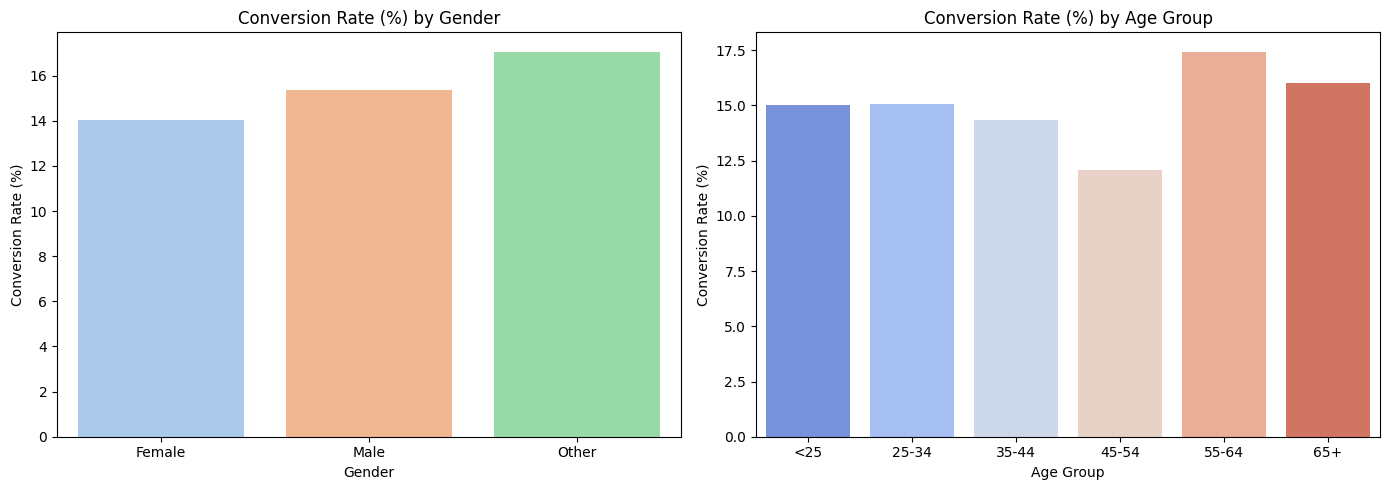

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create Age Groups
bins = [0, 25, 35, 45, 55, 65, 100]
labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

# 2. Calculate Conversion Rate by Gender
gender_conv = df.groupby('Gender').agg(
    Total_Customers=('Customer_ID', 'count'),
    Conversions=('Conversion', 'sum')
).reset_index()
gender_conv['Conversion_Rate_pct'] = ((gender_conv['Conversions'] / gender_conv['Total_Customers']) * 100).round(2)

print("--- Conversion Rate by Gender ---")
display(gender_conv)

# 3. Calculate Conversion Rate by Age Group
age_conv = df.groupby('Age_Group', observed=False).agg(
    Total_Customers=('Customer_ID', 'count'),
    Conversions=('Conversion', 'sum')
).reset_index()
age_conv['Conversion_Rate_pct'] = ((age_conv['Conversions'] / age_conv['Total_Customers']) * 100).round(2)

print("\n--- Conversion Rate by Age Group ---")
display(age_conv)

# 4. Plot Visualizations
plt.figure(figsize=(14, 5))

# Gender Conversion Rate Plot
plt.subplot(1, 2, 1)
sns.barplot(data=gender_conv, x='Gender', y='Conversion_Rate_pct', palette='pastel', hue='Gender', legend=False)
plt.title('Conversion Rate (%) by Gender')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Gender')

# Age Group Conversion Rate Plot
plt.subplot(1, 2, 2)
sns.barplot(data=age_conv, x='Age_Group', y='Conversion_Rate_pct', palette='coolwarm', hue='Age_Group', legend=False)
plt.title('Conversion Rate (%) by Age Group')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Age Group')

plt.tight_layout()
plt.show()

In [3]:
from scipy.stats import chi2_contingency

# 1. Create a contingency table (Age Group vs Conversion Status)
contingency_table = pd.crosstab(df['Age_Group'], df['Conversion'])
print("--- Contingency Table (Age Group vs Conversion) ---")
display(contingency_table)

# 2. Perform the Chi-Square Test of Independence
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print("\n--- Chi-Square Test Results ---")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"Degrees of Freedom: {dof}")

# 3. Interpret the result
alpha = 0.05
if p_val < alpha:
    print(f"\nResult: Statistically Significant (p < {alpha}). There is a significant difference in conversion rates between age groups.")
else:
    print(f"\nResult: Not Statistically Significant (p >= {alpha}). There is no strong evidence of a difference in conversion rates between age groups.")

--- Contingency Table (Age Group vs Conversion) ---


Conversion,0,1
Age_Group,,
<25,113,20
25-34,152,27
35-44,167,28
45-54,189,26
55-64,142,30
65+,89,17



--- Chi-Square Test Results ---
Chi-Square Statistic: 2.3777
p-value: 0.7948
Degrees of Freedom: 5

Result: Not Statistically Significant (p >= 0.05). There is no strong evidence of a difference in conversion rates between age groups.


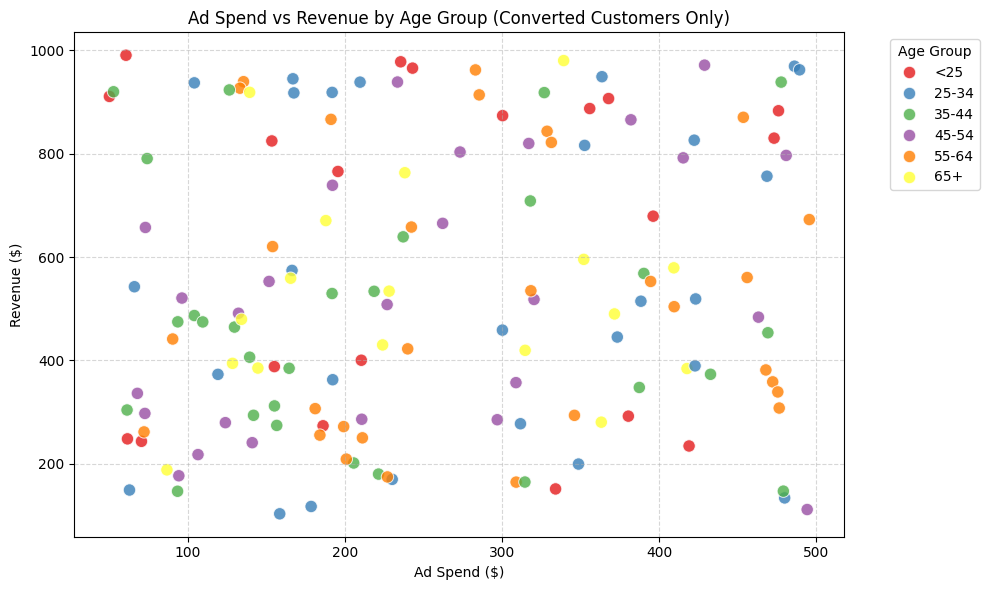

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for converted customers (where Revenue is greater than 0)
converted_df = df[df['Conversion'] == 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=converted_df,
    x='Ad_Spend',
    y='Revenue',
    hue='Age_Group',
    palette='Set1',
    alpha=0.8,
    s=80
)

plt.title('Ad Spend vs Revenue by Age Group (Converted Customers Only)')
plt.xlabel('Ad Spend ($)')
plt.ylabel('Revenue ($)')
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [5]:
from scipy.stats import chi2_contingency

# 1. Create a contingency table (Campaign Channel vs Conversion Status)
channel_contingency = pd.crosstab(df['Campaign_Channel'], df['Conversion'])
print("--- Contingency Table (Campaign Channel vs Conversion) ---")
display(channel_contingency)

# 2. Perform the Chi-Square Test of Independence
chi2_ch, p_val_ch, dof_ch, expected_ch = chi2_contingency(channel_contingency)

print("\n--- Chi-Square Test Results for Campaign Channel ---")
print(f"Chi-Square Statistic: {chi2_ch:.4f}")
print(f"p-value: {p_val_ch:.4f}")
print(f"Degrees of Freedom: {dof_ch}")

# 3. Interpret the result
alpha = 0.05
if p_val_ch < alpha:
    print(f"\nResult: Statistically Significant (p < {alpha}). There is a significant difference in conversion rates between campaign channels.")
else:
    print(f"\nResult: Not Statistically Significant (p >= {alpha}). There is no strong evidence of a difference in conversion rates between campaign channels.")

--- Contingency Table (Campaign Channel vs Conversion) ---


Conversion,0,1
Campaign_Channel,,
Email,256,42
PPC,172,36
Referral,77,11
Social Media,347,59



--- Chi-Square Test Results for Campaign Channel ---
Chi-Square Statistic: 1.5474
p-value: 0.6714
Degrees of Freedom: 3

Result: Not Statistically Significant (p >= 0.05). There is no strong evidence of a difference in conversion rates between campaign channels.


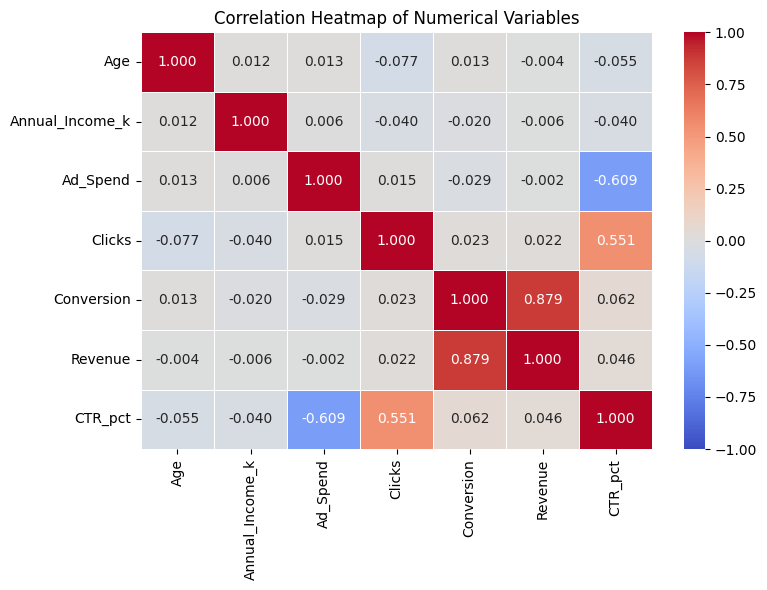

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for correlation mapping
numerical_cols = ['Age', 'Annual_Income_k', 'Ad_Spend', 'Clicks', 'Conversion', 'Revenue', 'CTR_pct']
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

In [7]:
# Calculate average revenue per converted customer for each campaign channel
avg_rev_per_conv = df[df['Conversion'] == 1].groupby('Campaign_Channel')['Revenue'].mean().reset_index()
avg_rev_per_conv.columns = ['Campaign_Channel', 'Avg_Revenue_Per_Conversion']
avg_rev_per_conv = avg_rev_per_conv.sort_values(by='Avg_Revenue_Per_Conversion', ascending=False).reset_index(drop=True)

# Format output with 2 decimal places
avg_rev_per_conv['Avg_Revenue_Per_Conversion'] = avg_rev_per_conv['Avg_Revenue_Per_Conversion'].round(2)

print("--- Average Revenue per Conversion by Campaign Channel ---")
display(avg_rev_per_conv)

--- Average Revenue per Conversion by Campaign Channel ---


,Campaign_Channel,Avg_Revenue_Per_Conversion
0,Referral,594.05
1,PPC,570.16
2,Social Media,525.03
3,Email,518.11


In [8]:
# Calculate ROI metrics by Campaign Channel
roi_summary = df.groupby('Campaign_Channel').agg(
    Total_Spend=('Ad_Spend', 'sum'),
    Total_Revenue=('Revenue', 'sum')
).reset_index()

# ROI (%) = ((Revenue - Spend) / Spend) * 100
roi_summary['ROI_Percentage'] = (((roi_summary['Total_Revenue'] - roi_summary['Total_Spend']) / roi_summary['Total_Spend']) * 100).round(2)
roi_summary = roi_summary.sort_values(by='ROI_Percentage', ascending=False).reset_index(drop=True)

print("--- Return on Investment (ROI) per Campaign Channel ---")
display(roi_summary)

--- Return on Investment (ROI) per Campaign Channel ---


,Campaign_Channel,Total_Spend,Total_Revenue,ROI_Percentage
0,PPC,55230.88,20525.60,-62.84
1,Referral,22960.98,6534.50,-71.54
2,Social Media,110498.82,30976.93,-71.97
3,Email,80047.85,21760.52,-72.82


--- Channel Metrics Comparison ---


,Campaign_Channel,Avg_Revenue_Per_Conversion,ROI_Percentage,Total_Spend,Total_Revenue
0,Referral,594.05,-71.54,22960.98,6534.50
1,PPC,570.16,-62.84,55230.88,20525.60
2,Social Media,525.03,-71.97,110498.82,30976.93
3,Email,518.11,-72.82,80047.85,21760.52


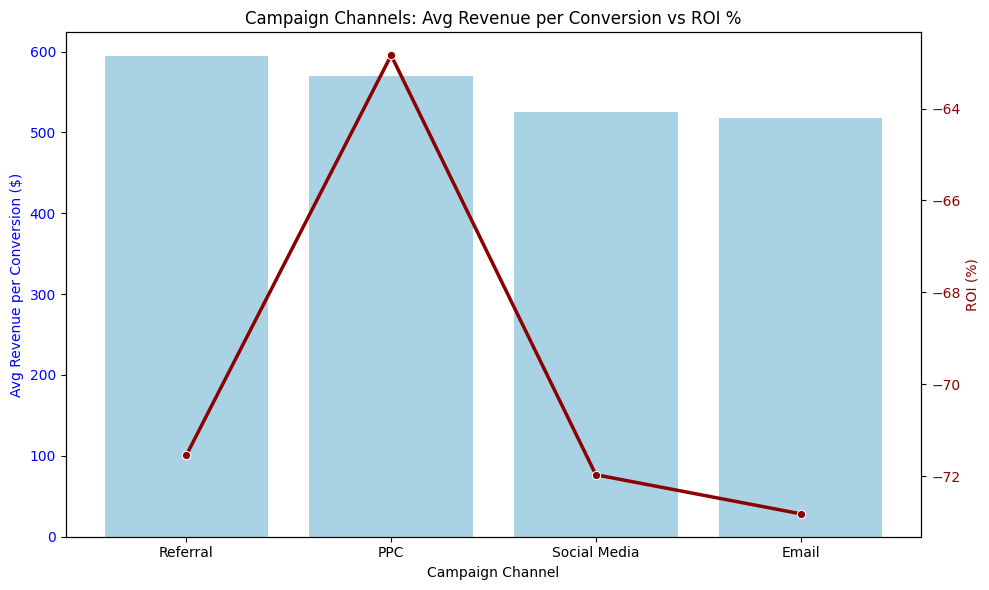

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Merge average revenue per conversion and ROI metrics
comparison_df = pd.merge(avg_rev_per_conv, roi_summary, on='Campaign_Channel')

print("--- Channel Metrics Comparison ---")
display(comparison_df[['Campaign_Channel', 'Avg_Revenue_Per_Conversion', 'ROI_Percentage', 'Total_Spend', 'Total_Revenue']])

# Plot the comparison
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Average Revenue per Conversion
color = 'skyblue'
sns.barplot(data=comparison_df, x='Campaign_Channel', y='Avg_Revenue_Per_Conversion', ax=ax1, color=color, alpha=0.8)
ax1.set_title('Campaign Channels: Avg Revenue per Conversion vs ROI %')
ax1.set_xlabel('Campaign Channel')
ax1.set_ylabel('Avg Revenue per Conversion ($)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Line plot for ROI Percentage using a twin axis
ax2 = ax1.twinx()
color = 'darkred'
sns.lineplot(data=comparison_df, x='Campaign_Channel', y='ROI_Percentage', ax=ax2, color=color, marker='o', linewidth=2.5)
ax2.set_ylabel('ROI (%)', color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.tight_layout()
plt.show()

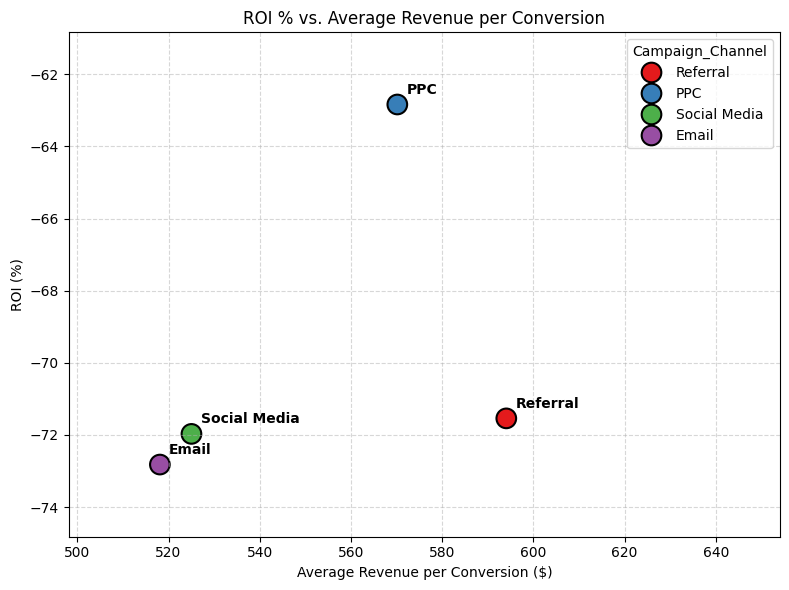

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# Create the scatter plot
sns.scatterplot(
    data=comparison_df,
    x='Avg_Revenue_Per_Conversion',
    y='ROI_Percentage',
    hue='Campaign_Channel',
    s=200,
    palette='Set1',
    edgecolor='black',
    linewidth=1.5
)

# Annotate the points with channel names
for i, row in comparison_df.iterrows():
    plt.text(
        row['Avg_Revenue_Per_Conversion'] + 2,
        row['ROI_Percentage'] + 0.3,
        row['Campaign_Channel'],
        horizontalalignment='left',
        size='medium',
        color='black',
        weight='semibold'
    )

plt.title('ROI % vs. Average Revenue per Conversion')
plt.xlabel('Average Revenue per Conversion ($)')
plt.ylabel('ROI (%)')
plt.grid(True, linestyle='--', alpha=0.5)

# Fix: ensure scalar bounds are passed to xlim and ylim
x_min = comparison_df['Avg_Revenue_Per_Conversion'].min() - 20
x_max = comparison_df['Avg_Revenue_Per_Conversion'].max() + 60
y_min = comparison_df['ROI_Percentage'].min() - 2
y_max = comparison_df['ROI_Percentage'].max() + 2

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.tight_layout()
plt.show()

```markdown
## Customer Segmentation via K-Means Clustering
We will segment customers based on their continuous profile attributes: **Age**, **Annual Income**, **Ad Spend**, and **Clicks**.
```

/tmp/ipykernel_798/3693546471.py:32: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "bo-" (-> marker='o'). The keyword argument will take precedence.
  ax1.plot(K_range, inertia, 'bo-', marker='o')
/tmp/ipykernel_798/3693546471.py:39: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "ro-" (-> marker='o'). The keyword argument will take precedence.
  ax2.plot(K_range, silhouette_scores, 'ro-', marker='s')


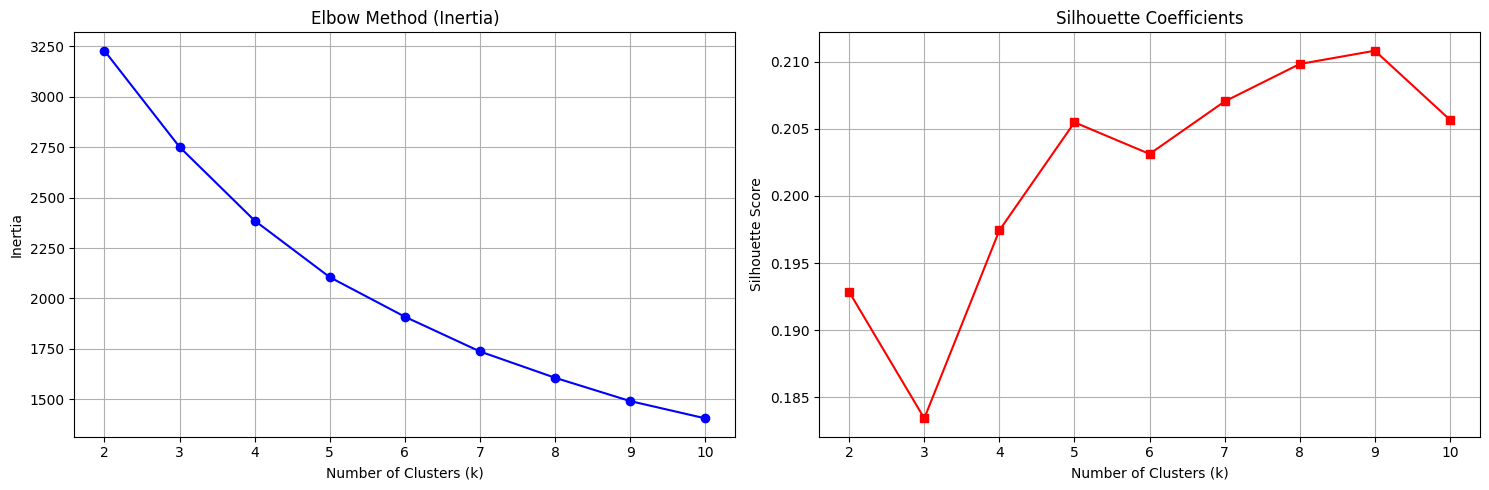

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Select features for clustering
features = ['Age', 'Annual_Income_k', 'Ad_Spend', 'Clicks']
X = df[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Determine optimal number of clusters using Elbow Method and Silhouette Score
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plot the Elbow Curve and Silhouette Scores side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(K_range, inertia, 'bo-', marker='o')
ax1.set_title('Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_xticks(K_range)
ax1.grid(True)

ax2.plot(K_range, silhouette_scores, 'ro-', marker='s')
ax2.set_title('Silhouette Coefficients')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(K_range)
ax2.grid(True)

plt.tight_layout()
plt.show()

```markdown
Based on the plots, let's assign $k=4$ clusters to segment our customer population. We will fit the final KMeans model, reduce dimensions using PCA for 2D visualization, and inspect the profile centroids.
```

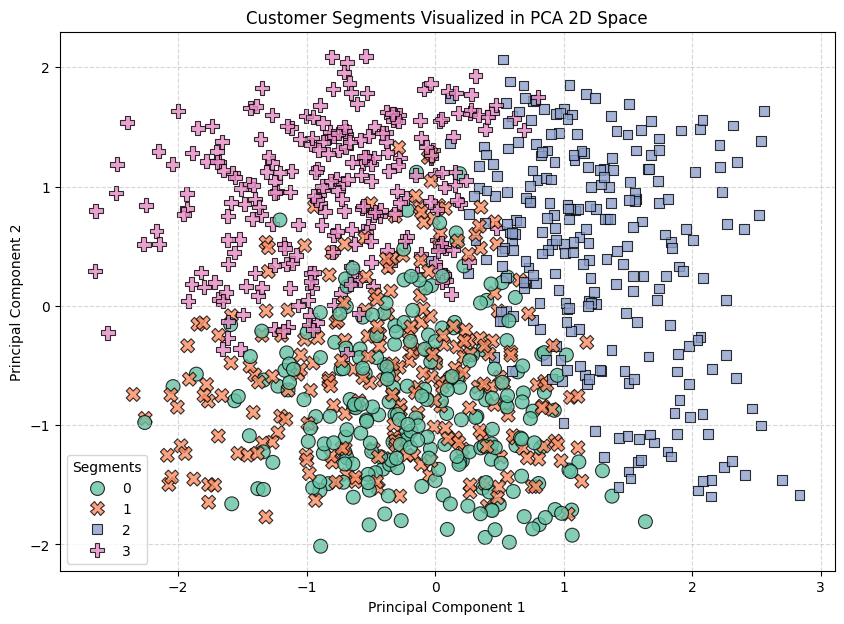

In [13]:
# Fit K-Means with the chosen number of clusters (k=4)
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Reduce dimensions to 2D using PCA for visualization
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)
df['PCA1'] = pca_components[:, 0]
df['PCA2'] = pca_components[:, 1]

# Plot PCA Scatter representation of Clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set2',
    style='Cluster',
    s=100,
    edgecolor='black',
    alpha=0.8
)
plt.title('Customer Segments Visualized in PCA 2D Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Segments')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [14]:
# Profile the resulting segments
cluster_profiles = df.groupby('Cluster').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income_k=('Annual_Income_k', 'mean'),
    Avg_Ad_Spend=('Ad_Spend', 'mean'),
    Avg_Clicks=('Clicks', 'mean'),
    Conversion_Rate_pct=('Conversion', 'mean')
).reset_index()

# Scale conversion metric back to a percentage representation
cluster_profiles['Conversion_Rate_pct'] = (cluster_profiles['Conversion_Rate_pct'] * 100).round(2)
cluster_profiles = cluster_profiles.round(2)

print("--- Final Cluster Profiles Summary ---")
display(cluster_profiles)

--- Final Cluster Profiles Summary ---


,Cluster,Customer_Count,Avg_Age,Avg_Income_k,Avg_Ad_Spend,Avg_Clicks,Conversion_Rate_pct
0,0,242,33.33,66.33,185.79,83.20,15.29
1,1,248,57.40,65.48,170.93,177.47,18.15
2,2,258,31.76,61.22,319.17,230.29,13.18
3,3,252,52.88,66.83,393.02,103.48,12.70


```markdown
## Visualizing Cluster Centroids in Original Feature Scales
To understand the typical profile of each segment, we map the scaled cluster centroids back to their original physical units: **Age (Years)**, **Annual Income (k$)**, **Ad Spend ($)**, and **Clicks**.
```

--- Cluster Centroids (Original Scales) ---


,Age,Annual_Income_k,Ad_Spend,Clicks,Cluster
0,33.334711,66.334711,185.791033,83.202479,Cluster 0
1,57.395161,65.475806,170.927782,177.467742,Cluster 1
2,31.755814,61.217054,319.172674,230.290698,Cluster 2
3,52.876984,66.829365,393.017698,103.484127,Cluster 3


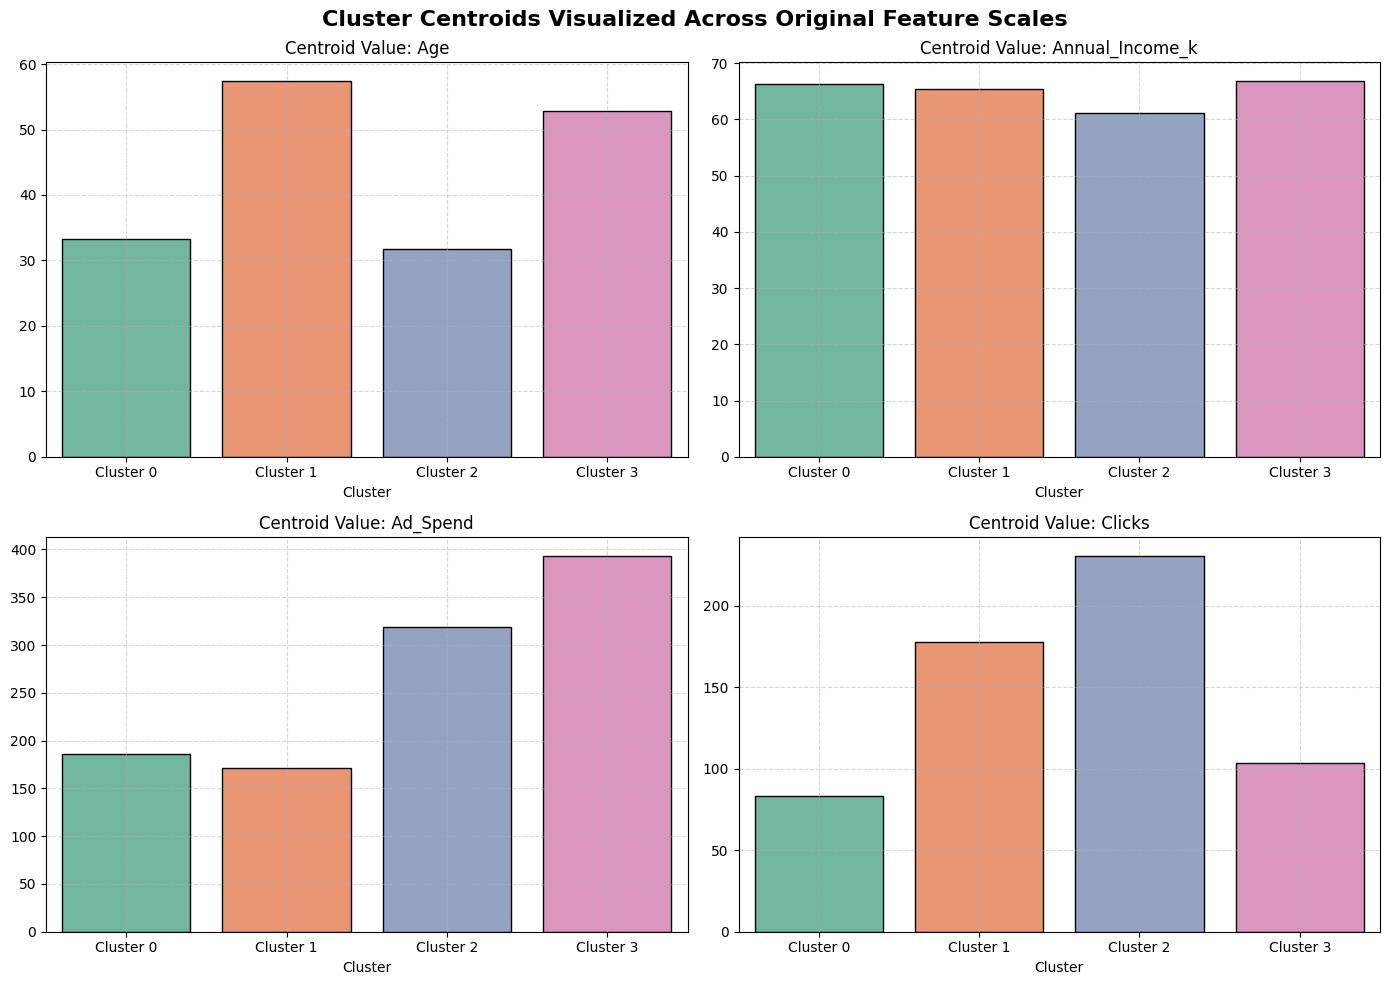

In [15]:
# Retrieve the cluster centers in scaled space
scaled_centroids = kmeans_final.cluster_centers_

# Inverse-transform the centroids back to the original scales
original_centroids = scaler.inverse_transform(scaled_centroids)

# Create a DataFrame for easy visualization
centroids_df = pd.DataFrame(original_centroids, columns=features)
centroids_df['Cluster'] = [f'Cluster {i}' for i in range(optimal_k)]

print("--- Cluster Centroids (Original Scales) ---")
display(centroids_df)

# Set up a grid of plots to visualize each feature's average value per cluster
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

colors = sns.color_palette('Set2', n_colors=optimal_k)

for idx, feature in enumerate(features):
    sns.barplot(
        data=centroids_df,
        x='Cluster',
        y=feature,
        ax=axes[idx],
        palette='Set2',
        hue='Cluster',
        legend=False,
        edgecolor='black'
    )
    axes[idx].set_title(f'Centroid Value: {feature}')
    axes[idx].set_ylabel('')
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Cluster Centroids Visualized Across Original Feature Scales', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

```markdown
## A/B Test Simulation for Cluster 3 Landing Page Strategy
To validate the strategic recommendations for **Cluster 3** (Older, Low-Engagement Premium Spenders), we simulate an A/B test comparing the current landing page layout (**Control / Group A**) to a simplified, high-trust, and clear value-proposition layout (**Variant / Group B**).
```

In [17]:
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

# 1. Setup Simulation Parameters for Cluster 3 Users
np.random.seed(42)
n_test_samples = 1000

# Baseline conversion (Control A) matches the observed ~12.7% conversion
p_control = 0.127
# Target conversion with new trust-focused layout (Variant B) assumed at 18.0%
p_variant = 0.180

# Generate simulated conversions
conversions_control = np.random.binomial(1, p_control, n_test_samples)
conversions_variant = np.random.binomial(1, p_variant, n_test_samples)

# Calculate summary metrics
clicks_control = n_test_samples
clicks_variant = n_test_samples

conv_count_control = sum(conversions_control)
conv_count_variant = sum(conversions_variant)

rate_control = (conv_count_control / n_test_samples) * 100
rate_variant = (conv_count_variant / n_test_samples) * 100

print("--- A/B Test Simulation Summary ---")
print(f"Control Group (A) Conversions: {conv_count_control} / {n_test_samples} ({rate_control:.2f}% Conversion)")
print(f"Variant Group (B) Conversions: {conv_count_variant} / {n_test_samples} ({rate_variant:.2f}% Conversion)")

# 2. Perform Two-Sample Z-Test for Proportions
count = np.array([conv_count_variant, conv_count_control])
nobs = np.array([n_test_samples, n_test_samples])

z_stat, p_value = proportions_ztest(count, nobs, alternative='two-sided')

print("\n--- Hypothesis Testing Results ---")
print(f"Z-statistic: {z_stat:.4f}")
print(f"p-value: {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    print(f"Result: Statistically Significant (p < {alpha}). The new landing page layout significantly improved conversion rates for Cluster 3!")
else:
    print(f"Result: Not Statistically Significant (p >= {alpha}). We cannot reject the null hypothesis; there is no strong evidence of conversion improvement.")

--- A/B Test Simulation Summary ---
Control Group (A) Conversions: 132 / 1000 (13.20% Conversion)
Variant Group (B) Conversions: 178 / 1000 (17.80% Conversion)

--- Hypothesis Testing Results ---
Z-statistic: 2.8422
p-value: 0.004481
Result: Statistically Significant (p < 0.05). The new landing page layout significantly improved conversion rates for Cluster 3!


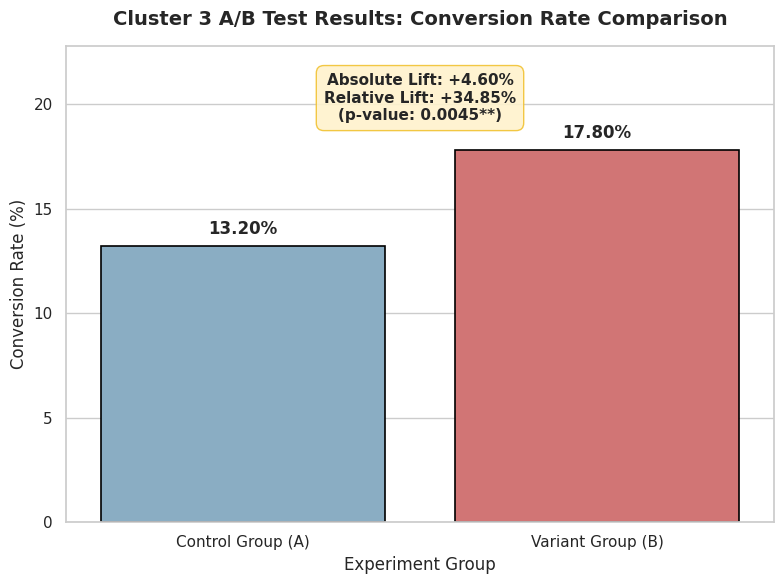

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data for plotting
groups = ['Control Group (A)', 'Variant Group (B)']
conversion_rates = [rate_control, rate_variant]

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Create a bar plot
barplot = sns.barplot(
    x=groups,
    y=conversion_rates,
    palette=['#80afcd', '#e06666'],
    edgecolor='black',
    linewidth=1.2,
    hue=groups,
    legend=False
)

# Add values on top of the bars
for p in barplot.patches:
    barplot.annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 0.5),
        ha='center',
        va='center',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=12,
        weight='bold'
    )

# Calculate and annotate lift
lift = rate_variant - rate_control
relative_lift = (lift / rate_control) * 100

plt.title('Cluster 3 A/B Test Results: Conversion Rate Comparison', fontsize=14, weight='bold', pad=15)
plt.ylabel('Conversion Rate (%)', fontsize=12)
plt.xlabel('Experiment Group', fontsize=12)
plt.ylim(0, max(conversion_rates) + 5)

# Add text block indicating the lift and significance
plt.text(
    0.5,
    max(conversion_rates) + 2.5,
    f"Absolute Lift: +{lift:.2f}%\nRelative Lift: +{relative_lift:.2f}%\n(p-value: {p_value:.4f}**)",
    ha='center',
    va='center',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff2cc', edgecolor='#f1c232', alpha=0.9),
    fontsize=11,
    weight='semibold'
)

plt.tight_layout()
plt.show()

In [19]:
# 1. Isolate Cluster 3 data
cluster3_df = df[df['Cluster'] == 3].copy()

# 2. Get original metrics for Cluster 3
total_spend_c3 = cluster3_df['Ad_Spend'].sum()
original_revenue_c3 = cluster3_df['Revenue'].sum()
original_conversions_c3 = cluster3_df['Conversion'].sum()
original_roi_c3 = ((original_revenue_c3 - total_spend_c3) / total_spend_c3) * 100

# 3. Project new metrics using Variant B Conversion Rate (~17.8%)
# We'll calculate the expected number of conversions and revenue
np.random.seed(42)
projected_conv_rate = rate_variant / 100  # 17.8%

# We simulate conversions for the Cluster 3 population
simulated_conversions = np.random.binomial(1, projected_conv_rate, len(cluster3_df))
projected_conversions_c3 = sum(simulated_conversions)

# For converted customers, we simulate revenue based on original converted customer behavior in Cluster 3
avg_rev_per_conv_c3 = cluster3_df[cluster3_df['Conversion'] == 1]['Revenue'].mean()
if pd.isna(avg_rev_per_conv_c3):
    # fallback to global mean if no conversions exist
    avg_rev_per_conv_c3 = df[df['Conversion'] == 1]['Revenue'].mean()

projected_revenue_c3 = projected_conversions_c3 * avg_rev_per_conv_c3
projected_roi_c3 = ((projected_revenue_c3 - total_spend_c3) / total_spend_c3) * 100

# 4. Display comparative summary
roi_comparison = pd.DataFrame({
    'Metric': [
        'Total Customers in Cluster 3',
        'Ad Spend ($)',
        'Conversions',
        'Conversion Rate',
        'Total Revenue ($)',
        'ROI (%)'
    ],
    'Original Baseline': [
        len(cluster3_df),
        f"${total_spend_c3:,.2f}",
        original_conversions_c3,
        f"{cluster_profiles.loc[3, 'Conversion_Rate_pct']:.2f}%",
        f"${original_revenue_c3:,.2f}",
        f"{original_roi_c3:.2f}%"
    ],
    'Projected (Variant B Layout)': [
        len(cluster3_df),
        f"${total_spend_c3:,.2f}",
        projected_conversions_c3,
        f"{rate_variant:.2f}%",
        f"${projected_revenue_c3:,.2f}",
        f"{projected_roi_c3:.2f}%"
    ]
})

print("--- Cluster 3 Segment-Specific ROI Analysis ---")
display(roi_comparison)

# Calculate additional revenue and absolute ROI improvement
additional_revenue = projected_revenue_c3 - original_revenue_c3
roi_improvement = projected_roi_c3 - original_roi_c3
print(f"\nAdditional Revenue Generated: ${additional_revenue:,.2f}")
print(f"Absolute ROI Improvement: {roi_improvement:+.2f} percentage points")

--- Cluster 3 Segment-Specific ROI Analysis ---


,Metric,Original Baseline,Projected (Variant B Layout)
0,Total Customers in Cluster 3,252,252
1,Ad Spend ($),"$99,040.46","$99,040.46"
2,Conversions,32,45
3,Conversion Rate,12.70%,17.80%
4,Total Revenue ($),"$17,047.02","$23,972.37"
5,ROI (%),-82.79%,-75.80%



Additional Revenue Generated: $6,925.35
Absolute ROI Improvement: +6.99 percentage points


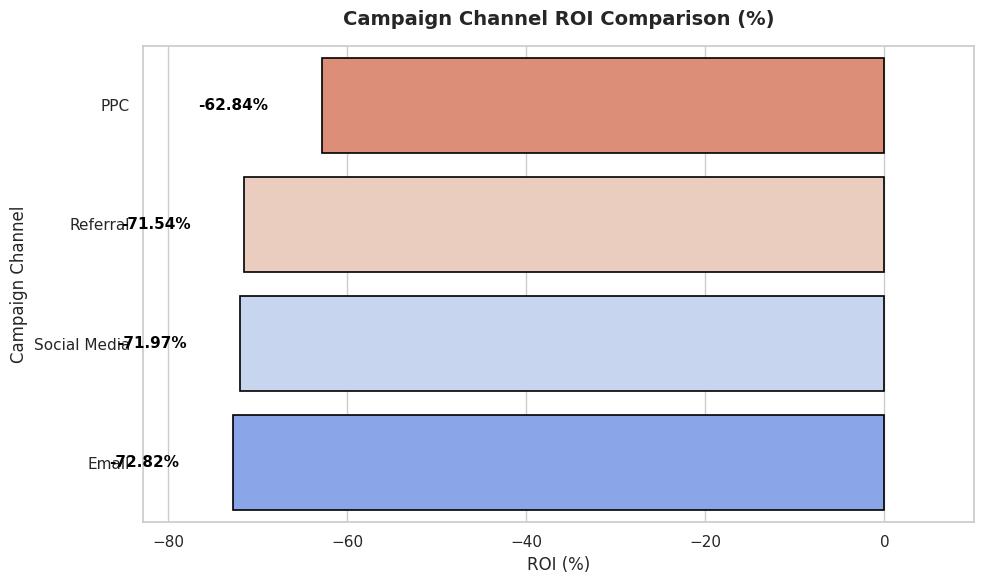

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort ROI summary for intuitive visual presentation
roi_summary_sorted = roi_summary.sort_values(by='ROI_Percentage', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Horizontal bar plot for easy comparison of ROI
roi_plot = sns.barplot(
    data=roi_summary_sorted,
    x='ROI_Percentage',
    y='Campaign_Channel',
    palette='coolwarm_r',
    edgecolor='black',
    linewidth=1.2,
    hue='Campaign_Channel',
    legend=False
)

# Annotate the actual values onto the bars
for index, value in enumerate(roi_summary_sorted['ROI_Percentage']):
    plt.text(
        value + 1 if value >= 0 else value - 6,
        index,
        f"{value:.2f}%",
        va='center',
        ha='left' if value >= 0 else 'right',
        fontsize=11,
        weight='bold',
        color='black'
    )

plt.title('Campaign Channel ROI Comparison (%)', fontsize=14, weight='bold', pad=15)
plt.xlabel('ROI (%)', fontsize=12)
plt.ylabel('Campaign Channel', fontsize=12)

# Give some breathing room on the x-axis to accommodate annotations
plt.xlim(roi_summary_sorted['ROI_Percentage'].min() - 10, max(0, roi_summary_sorted['ROI_Percentage'].max()) + 10)

plt.tight_layout()
plt.show()

--- Conversion Rate Comparison Across Segments ---


,Cluster,Customer_Count,Conversion_Rate_pct
0,0,242,15.29
1,1,248,18.15
2,2,258,13.18
3,3,252,12.70
4,Cluster 3 (Variant B),1000,17.80


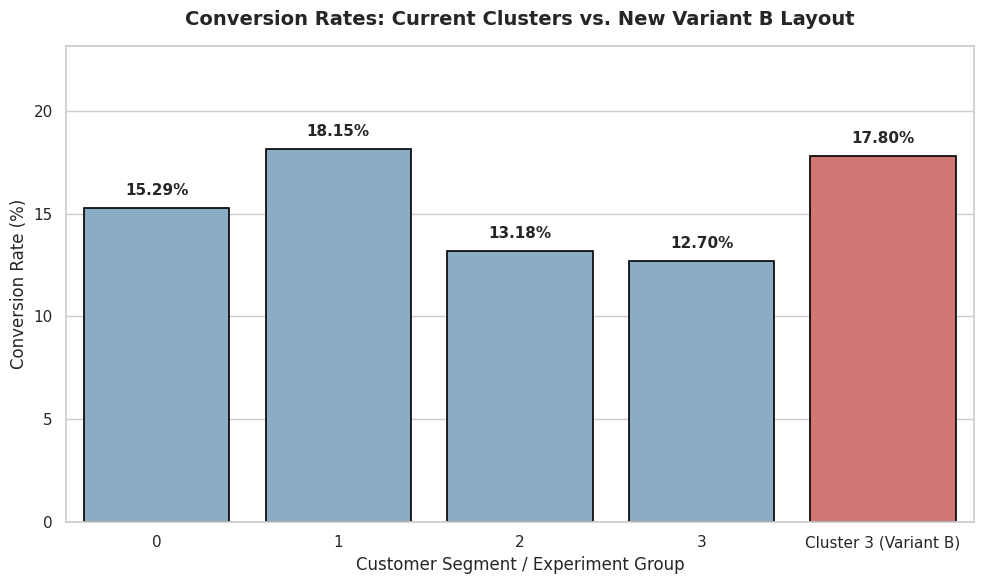

In [21]:
# 1. Prepare comparison data
cluster_summary_comparison = cluster_profiles[['Cluster', 'Customer_Count', 'Conversion_Rate_pct']].copy()

# Add a row for the newly tested Variant B layout
variant_b_row = pd.DataFrame({
    'Cluster': ['Cluster 3 (Variant B)'],
    'Customer_Count': [1000],  # test sample size
    'Conversion_Rate_pct': [rate_variant]
})

comparison_table = pd.concat([cluster_summary_comparison, variant_b_row], ignore_index=True)
print("--- Conversion Rate Comparison Across Segments ---")
display(comparison_table)

# 2. Visualize the comparison
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Highlight the Variant B layout with a distinct color
colors = ['#80afcd' if 'Variant B' not in str(c) else '#e06666' for c in comparison_table['Cluster']]

barplot = sns.barplot(
    data=comparison_table,
    x='Cluster',
    y='Conversion_Rate_pct',
    palette=colors,
    edgecolor='black',
    linewidth=1.2,
    hue='Cluster',
    legend=False
)

# Annotate the values on top of the bars
for p in barplot.patches:
    barplot.annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 0.5),
        ha='center',
        va='center',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=11,
        weight='bold'
    )

plt.title('Conversion Rates: Current Clusters vs. New Variant B Layout', fontsize=14, weight='bold', pad=15)
plt.ylabel('Conversion Rate (%)', fontsize=12)
plt.xlabel('Customer Segment / Experiment Group', fontsize=12)
plt.ylim(0, max(comparison_table['Conversion_Rate_pct']) + 5)
plt.tight_layout()
plt.show()

--- Cluster 1 Demographic & Behavior Summary ---


,Age,Annual_Income_k,Ad_Spend,Clicks
mean,57.395161,65.475806,170.927782,177.467742
min,37.000000,19.000000,50.010000,11.000000
max,69.000000,104.000000,378.610000,298.000000



--- Campaign Channel Distribution in Cluster 1 ---


,Percentage (%)
Campaign_Channel,
Social Media,39.516129
Email,31.048387
PPC,20.967742
Referral,8.467742



--- Gender Distribution in Cluster 1 ---


,Percentage (%)
Gender,
Male,50.00000
Female,45.16129
Other,4.83871


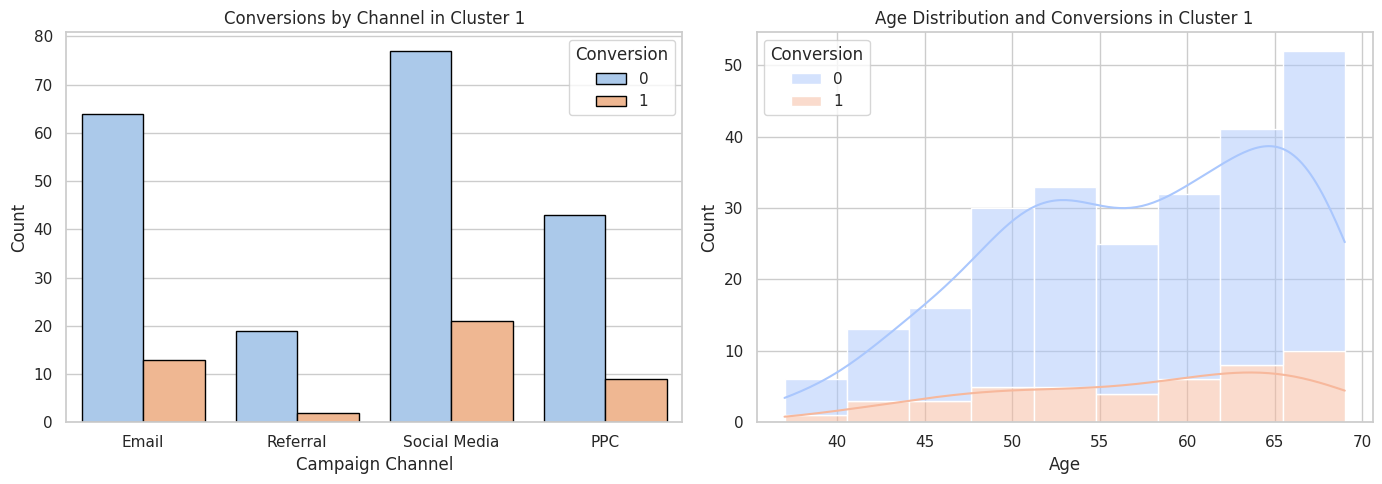

In [22]:
# 1. Isolate Cluster 1
cluster1_df = df[df['Cluster'] == 1].copy()

# 2. Print statistical summary of numeric characteristics
print("--- Cluster 1 Demographic & Behavior Summary ---")
summary_stats = cluster1_df[['Age', 'Annual_Income_k', 'Ad_Spend', 'Clicks']].describe().loc[['mean', 'min', 'max']]
display(summary_stats)

# 3. Analyze preferred channels and gender distribution
print("\n--- Campaign Channel Distribution in Cluster 1 ---")
channel_dist = cluster1_df['Campaign_Channel'].value_counts(normalize=True) * 100
display(channel_dist.to_frame(name='Percentage (%)'))

print("\n--- Gender Distribution in Cluster 1 ---")
gender_dist = cluster1_df['Gender'].value_counts(normalize=True) * 100
display(gender_dist.to_frame(name='Percentage (%)'))

# 4. Plot profiles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

sns.countplot(data=cluster1_df, x='Campaign_Channel', hue='Conversion', palette='pastel', ax=ax1, edgecolor='black')
ax1.set_title('Conversions by Channel in Cluster 1')
ax1.set_xlabel('Campaign Channel')
ax1.set_ylabel('Count')

sns.histplot(data=cluster1_df, x='Age', hue='Conversion', multiple='stack', palette='coolwarm', ax=ax2, kde=True)
ax2.set_title('Age Distribution and Conversions in Cluster 1')
ax2.set_xlabel('Age')
ax2.set_ylabel('Count')

plt.tight_layout()
plt.show()